Device: NVIDIA GeForce GTX 1650
Images to benchmark: 50

--- YOLO Performance Results ---
Images processed: 50
Mean latency:   29.11 ms/image
Median latency: 25.26 ms/image
P95 latency:    44.05 ms/image
Throughput:     34.35 images/second
Mean detections per image: 4.52

Saved benchmark CSV: c:\Users\yatha\Desktop\autonomous-driving-perception\runs\benchmarking\yolo_benchmark.csv


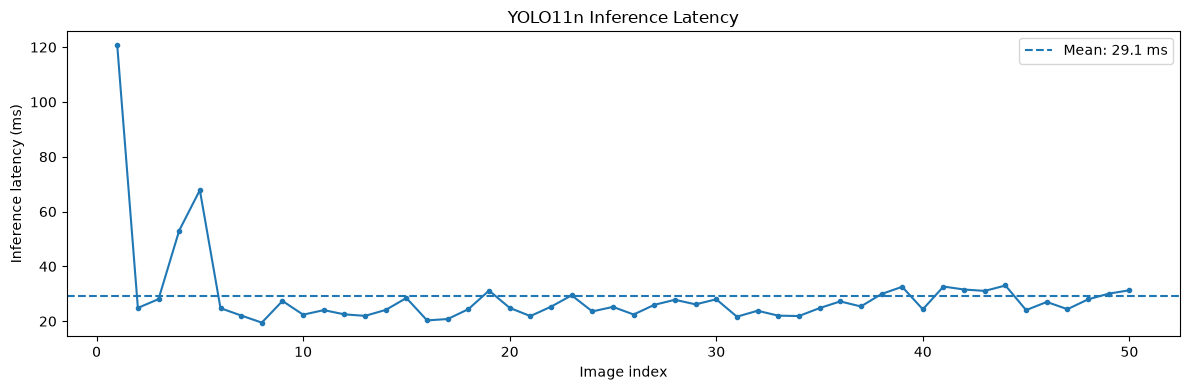

In [1]:

from pathlib import Path
import time
import cv2
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Project paths
project_dir = Path.cwd().parent
model_path = (
    project_dir / "runs" / "kitti_improved"
    / "weights" / "best.pt"
)
val_dir = project_dir / "data" / "kitti_yolo" / "images" / "val"

assert model_path.exists(), f"Model not found: {model_path}"

image_paths = sorted(val_dir.glob("*.jpg"))[:50]
assert image_paths, f"No images found in {val_dir}"

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO(str(model_path))

print("Device:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "CPU")
print("Images to benchmark:", len(image_paths))

# Warm-up: exclude startup overhead from the measurements
warmup_image = cv2.imread(str(image_paths[0]))
_ = model.predict(
    source=warmup_image,
    imgsz=416,
    conf=0.25,
    device=device,
    verbose=False
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

# Benchmark individual images
latencies_ms = []
detection_counts = []

for image_path in image_paths:
    img = cv2.imread(str(image_path))
    if img is None:
        continue

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    result = model.predict(
        source=img,
        imgsz=416,
        conf=0.25,
        device=device,
        verbose=False
    )[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    elapsed_ms = (time.perf_counter() - start) * 1000
    latencies_ms.append(elapsed_ms)
    detection_counts.append(len(result.boxes))

# Summarize performance
latencies_ms = np.array(latencies_ms)

mean_latency = float(np.mean(latencies_ms))
median_latency = float(np.median(latencies_ms))
p95_latency = float(np.percentile(latencies_ms, 95))
throughput_fps = 1000.0 / mean_latency

print("\n--- YOLO Performance Results ---")
print("Images processed:", len(latencies_ms))
print(f"Mean latency:   {mean_latency:.2f} ms/image")
print(f"Median latency: {median_latency:.2f} ms/image")
print(f"P95 latency:    {p95_latency:.2f} ms/image")
print(f"Throughput:     {throughput_fps:.2f} images/second")
print(f"Mean detections per image: {np.mean(detection_counts):.2f}")

# Save per-image results
benchmark_df = pd.DataFrame({
    "image": [p.name for p in image_paths[:len(latencies_ms)]],
    "latency_ms": latencies_ms,
    "detections": detection_counts
})

output_dir = project_dir / "runs" / "benchmarking"
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "yolo_benchmark.csv"
benchmark_df.to_csv(csv_path, index=False)

print("\nSaved benchmark CSV:", csv_path)

# Plot latency by image
plt.figure(figsize=(12, 4))
plt.plot(range(1, len(latencies_ms) + 1), latencies_ms, marker=".")
plt.axhline(mean_latency, linestyle="--",
            label=f"Mean: {mean_latency:.1f} ms")
plt.xlabel("Image index")
plt.ylabel("Inference latency (ms)")
plt.title("YOLO11n Inference Latency")
plt.legend()
plt.tight_layout()
plt.show()
